In [3]:
import numpy as np
import scipy as sc
import matplotlib.pyplot as plt

In [4]:
# params
alpha = 1
beta = 0.5
eps_0 = 2 * alpha * beta**(1.5)

# equilibrium point
x_star = np.arccos(beta)
y_star = 0
z_star = 1/np.sqrt(beta)

def ode_system(t, state, alpha, beta, epsilon):
    x = state[0]
    y = state[1]
    z = state[2]
    dx_dt = y
    dy_dt = np.sin(x) * (z**2 * np.cos(x) - 1) - epsilon * y
    dz_dt = alpha * (np.cos(x) - beta)
    return [dx_dt, dy_dt, dz_dt]

In [15]:
t_start = 0
t_end = 200
t_vals = np.linspace(t_start, t_end, 2000)

x0 = [x_star + 0.1, y_star + 0.1, z_star + 0.1]

eps_s = eps_0 * 1.5
eps_u = eps_0 * 0.5

sol_s = sc.integrate.solve_ivp(ode_system, [t_start, t_end], x0, t_eval=t_vals, args=(alpha, beta, eps_s))

sol_u = sc.integrate.solve_ivp(ode_system, [t_start, t_end], x0, t_eval=t_vals, args=(alpha, beta, eps_u))

sol_z = sc.integrate.solve_ivp(ode_system, [t_start, t_end], x0, t_eval=t_vals, args=(alpha, beta, eps_0))

Text(0.5, 0.92, '3D Trajectories')

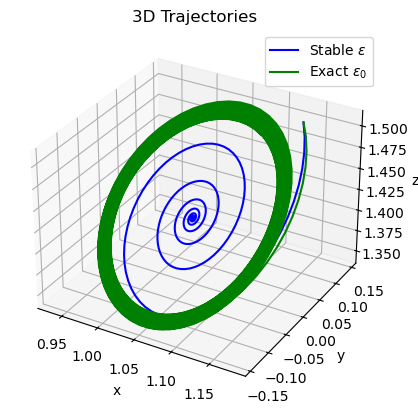

In [20]:
# plot them pretties

fig = plt.figure()
ax = fig.add_subplot(projection='3d')
ax.plot(sol_s.y[0], sol_s.y[1], sol_s.y[2], label='Stable $\\epsilon$', color='blue')
#ax.plot(sol_u.y[0], sol_u.y[1], sol_u.y[2], label='Unstable $\\epsilon$', color='orange')
ax.plot(sol_z.y[0], sol_z.y[1], sol_z.y[2], label='Exact $\\epsilon_0$', color='green')
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_zlabel('z')
ax.legend()
plt.title('3D Trajectories')
